## Computational Homework 2, 2026

#### Due September 23

Unless expressly stated otherwise, please make sure your plot axes have labels and multiple lines on the same plot are explained in a legend.

In [62]:
from sympy import *
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
init_printing(use_unicode=True)


#### Including friction in Lagrangian mechanics

<ol>
    <li>Assume a single particle moving in one dimension is subjected to a net <bf>conservative</bf> force \[ F = -\frac{\partial U}{\partial x} \] and a friction force $F_{\rm fric}$. Define the Lagrangian as \[\mathcal{L} =  \mathcal{T} - U \] and show that the appropriate modification to the Euler-Lagrange equation is \[ \frac{\partial \mathcal{L}}{\partial x} + F_{\rm fric} = \frac{d}{dt} \frac{\partial \mathcal{L}}{\partial \dot{x}}.\] Write out your solution step by step in a Markdown cell in this notebook (like this one). Markdown syntax is quite similar to LaTeX; see the <a href=https://www.markdownguide.org/basic-syntax/>Markdown guide</a>.</li>
</ol>

$$\mathcal{L}  = T - U$$
$$\mathcal{L'} = \mathcal{L} + contribution \space from \space F_{fric}$$
The equation below was derived in class.
$$\partial S = \int_{t_1}^{t_2} \partial \mathcal{L'} = \int_{t_1}^{t_2} [-m(\vec{\epsilon} \cdot
\ddot{\vec{r}}) - \nabla U \cdot \vec{\epsilon}] dt = 0$$
$$m\ddot{\vec{r}} = \vec{F_{tot}} = \vec{F_{fric}} + \vec{F}, \space - \nabla U  = F$$
$$\int_{t_1}^{t_2} \partial \mathcal{L'} = \int_{t_1}^{t_2} [-\vec{\epsilon} \cdot \vec{F_{fric}} + -\vec{\epsilon} \cdot \vec{F} + \vec{F} \cdot \vec{\epsilon}]dt$$
$$\int_{t_1}^{t_2} \partial \mathcal{L} = \int_{t_1}^{t_2}[-\vec{\epsilon} \cdot \vec{F} + \vec{F} \cdot \vec{\epsilon}]dt = \int_{t_1}^{t_2} \vec{\epsilon}[\frac{\partial \mathcal{L}}{\partial x} - \frac{d}{dt}\frac{\partial \mathcal{L}}{\partial \dot{x}}]dt$$
$$-\vec{\epsilon} \cdot \vec{F} + \vec{F} \cdot \vec{\epsilon} = \vec{\epsilon}[\frac{\partial \mathcal{L}}{\partial x} - \frac{d}{dt}\frac{\partial \mathcal{L}}{\partial \dot{x}}]$$
$$\int_{t_1}^{t_2} \partial \mathcal{L'} = \int_{t_1}^{t_2} \vec{\epsilon}[F_{fric} + \frac{\partial \mathcal{L}}{\partial x} - \frac{d}{dt}\frac{\partial \mathcal{L}}{\partial \dot{x}}] = 0$$
$\vec{\epsilon}$, our perturbation, must be allowed to be any shape. Therefore:
$$F_{fric} + \frac{\partial \mathcal{L}}{\partial x} - \frac{d}{dt}\frac{\partial \mathcal{L}}{\partial \dot{x}} = 0$$

#### Oscillations about an equilibrium point

Consider Example 7.6 in your textbook, the bead on the spinning wire. Equation 7.69 gives the equation of motion (EOM): $\ddot{\theta} = (\omega^2 \cos \theta - g/R).$ While the EOM doesn't have an analytical solution, it can be solved numerically. The behavior of the system is determined by the ratio $\frac{\omega^2}{g/R}.$

<ol start=2>
    <li>Choose a value of $\frac{\omega^2}{g/R}$ that is much less than 1. Select a value of $R$ that is of order 1 meter. The exact number is up to you. Start the bead at a small displacement from the equilibrium position at the bottom of the hoop. The exact angle of your displacement is up to you. Use <tt>sympy</tt> to <em>numerically</em> solve your equation of motion to find $\theta(t)$ for 5 full rotations of the hoop. Plot your answer.</li>
    <li>Now pick a value of $\frac{\omega^2}{g/R}$ that is comfortably higher than 1. Again, start the bead at a small displacement from the bottom of the hoop. Use <tt>sympy</tt> to numerically find $\theta(t)$ for five rotations of the hoop and plot your answer. In a Markdown cell, explain how your answer differs from question 2.</li>
</ol>

Text(0.5, 0.98, 'Bead on Spinning Wire Hoop')

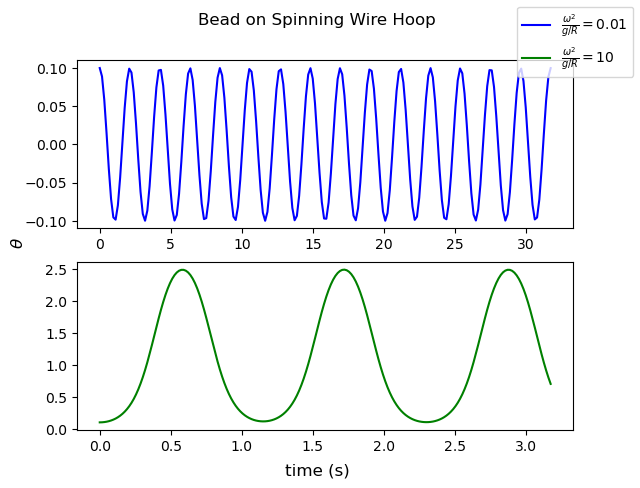

In [ ]:
y = symbols('y:2')
#d, v = symbols('d v')
c = symbols('c')
t = symbols('t')

d = y[0] #d for theta #unitless quantity
v = y[1] #ddot #unit: s^-1
c_vals = [[0.1], [10]] #initial value for omega^2/(g/r) #unitless quantity
g_r = 9.8 #unit s^-2
steps = 200 #number of steps

y0 = [0.1, 0] # initial condition 

ydot = [v, sin(d) * g_r * (c*cos(d) - 1)] #eom
f = lambdify((t, y, c), ydot)

#for c << 1
t_end = 10*np.pi/ (c_vals[0][0]*g_r)**0.5 #set 5 rotations
t_eval = np.linspace(0, t_end, steps) 
solution0 = solve_ivp(f, (0, t_end), y0, t_eval=t_eval, args=c_vals[0])

#for c >> 1
t_end = 10*np.pi/ (c_vals[1][0]*g_r)**0.5 #set 5 rotations
t_eval = np.linspace(0, t_end, steps) 
solution1 = solve_ivp(f, (0, t_end), y0, t_eval=t_eval, args=c_vals[1])

#print(solution.y[0])

#make plot
fig, ax = plt.subplots(2)

ax[0].plot(solution0.t, solution0.y[0], c = 'b', label = r'$\frac{\omega^2}{g/R} = 0.01$')
ax[1]. plot(solution1.t, solution1.y[0], c = 'g', label = r'$\frac{\omega^2}{g/R} = 10$')

fig.supxlabel('time (s)')
fig.supylabel(r'$\theta$')
fig.legend()
fig.suptitle('Bead on Spinning Wire Hoop')

When $\frac{\omega^2}{g/R}$ is much less than 1, the beat oscilates around $\theta = 0$. This angle is the location of stable equilibirum. However, when $\frac{\omega^2}{g/R}$ is much greater than 1, $\theta = 0$ is no longer a stable point, and the bead accelerates away from the bottom of the hoop. It then oscillates around a new equilibrium point that is further up the hoop. 

#### Testing <tt>sympy.calculus.euler.euler_equations</tt>

In Figure 7.12 of your textbook, a yoyo is represented by a cylinder of radius $R$ rolling down a string with negligible mass at angular speed $\omega$.

<ol start=4>
    <li>Write the Lagrangian for one generalized coordinate, the vertical distance of the string-cylinder contact point from the yoyo-er's hand, and try to use <tt>sympy.calculus.euler.euler_equations</tt> to find the Euler-Lagrange equation.</li>
    <li>Derive the Euler-Lagrange equation by hand. Does your solution match <tt>sympy</tt>'s solution? If <tt>sympy</tt> was unsuccesful at solving the Euler-Lagrange equation, how might you improve your calculation? Remember that, like any physicist, a computer algebra system likes to be fed information in the simplest form possible.</li>
</ol>

In [65]:
# Your code here
t, m, g= symbols('t m g')
x = Function('x')(t)

T = 0.75*m*x.diff(t)**2
U = m*g*x
lagrange = T - U

eqns = euler_equations(lagrange, x, t)
xdotdot = solve(eqns[0], x.diff(t, 2))

print("Acceleration in the x direction equals", xdotdot[0])


Acceleration in the x direction equals -0.666666666666667*g


$$T = \frac{mx^2}{2} + \frac{I\omega^2}{2}$$
$$I = \frac{nR^2}{2}, \omega = \frac{\dot{x}}{R}$$
$$T = \frac{3m\dot{x}^2}{4}$$
$$U = mgx$$
$$L = \frac{3}{4}m\dot{x}^2 - mgx$$
$$\frac{dL}{dx} - \frac{d}{dt}(\frac{dL}{d\dot{x}}) = 0$$
$$-mg - \frac{3}{2}\ddot{x} = 0$$
$$\ddot{x} = -\frac{2}{3}g$$

My solution matches sympy's solution. 

In [66]:
#scratch work
'''from sympy import *
import numpy as np
from scipy.integrate import solve_ivp
 
def oscillator(t, state):
    x, v = state
    return [v, -0.5 * v - 4 * x]
 
solution = solve_ivp(
    oscillator, (0, 10), [1, 0],
    t_eval=np.linspace(0, 10, 6),
)
 
print(np.round(solution.y[0], 4))

c_val = 0.01

def eom(t, state):
    d, v = state
    return[v, c_val*cos(d) - 1]

solution = solve_ivp(
    eom, (0, 100), [0.1, 0],
    t_eval=np.linspace(0, 10, 20),
)

print(np.round(solution.y[0], 4))
print(np.round(solution.y[1], 4))

fig, ax = plt.subplots()

ax.plot(solution.t, solution.y[0])'''

'from sympy import *\nimport numpy as np\nfrom scipy.integrate import solve_ivp\n \ndef oscillator(t, state):\n    x, v = state\n    return [v, -0.5 * v - 4 * x]\n \nsolution = solve_ivp(\n    oscillator, (0, 10), [1, 0],\n    t_eval=np.linspace(0, 10, 6),\n)\n \nprint(np.round(solution.y[0], 4))\n\nc_val = 0.01\n\ndef eom(t, state):\n    d, v = state\n    return[v, c_val*cos(d) - 1]\n\nsolution = solve_ivp(\n    eom, (0, 100), [0.1, 0],\n    t_eval=np.linspace(0, 10, 20),\n)\n\nprint(np.round(solution.y[0], 4))\nprint(np.round(solution.y[1], 4))\n\nfig, ax = plt.subplots()\n\nax.plot(solution.t, solution.y[0])'